# Thực nghiệm — Thử siêu tham số cho 4 mô hình trên tập A+B
Thực nghiệm sử dụng development.csv với 38 đặc trưng của tập A+B, gồm 36 đặc trưng gốc và hai đặc trưng bổ sung của học kỳ 1.

Bốn mô hình sử dụng cấu hình Gốc theo mốc chung và cấu hình Thử chỉ thay đổi một tham số. Cả bốn mô hình được đánh giá bằng cùng cách chia 5 fold.
## 1. Cấu hình và siêu tham số
Mỗi mô hình gồm cấu hình Gốc và cấu hình Thử; các tham số còn lại được giữ nguyên.

In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from xgboost import XGBClassifier

# Tìm thư mục gốc dự án.
cwd = Path.cwd().resolve()
candidates = (cwd, *cwd.parents, cwd / "ML01_Student_Dropout")
project_dir = next(
    (
        folder for folder in candidates
        if (folder / "feature_b" / "common.py").is_file()
        and (folder / "data" / "processed" / "development.csv").is_file()
    ),
    None,
)
if project_dir is None:
    raise FileNotFoundError(
        "Không tìm thấy thư mục ML01_Student_Dropout chứa feature_b/common.py "
        "và data/processed/development.csv. Hãy mở đúng repository trong VS Code."
    )

sys.path.insert(0, str(project_dir / "feature_b"))
from common import evaluate, load_development

data_path = project_dir / "data" / "processed" / "development.csv"
output_dir = project_dir / "experiments" / "2026-11-17_ThuThamSo_4MoHinh_TapAB_Khoi"
a_output_dir = project_dir / "experiments" / "2026-11-17_ThuThamSo_4MoHinh_TapA_Khoi"

N_FOLDS = 5
SEED = 42

print("Project:", project_dir)
print("Dữ liệu:", data_path)
print("Thư mục lưu kết quả:", output_dir)
configs = {
    "Logistic Regression": {
        "class": LogisticRegression,
        "scale_numeric": True,
        "baseline": {
            "C": 0.1, "tol": 0.0001, "class_weight": "balanced",
            "solver": "lbfgs", "max_iter": 3000,
        },
        "trial": {
            "C": 0.1, "tol": 0.001, "class_weight": "balanced",
            "solver": "lbfgs", "max_iter": 3000,
        },
        "changed_parameter": "tol: 0.0001 -> 0.001",
    },
    "Random Forest": {
        "class": RandomForestClassifier,
        "scale_numeric": False,
        "baseline": {
            "n_estimators": 200, "max_depth": None,
            "min_samples_split": 2, "min_samples_leaf": 1,
            "class_weight": "balanced", "random_state": SEED, "n_jobs": 1,
        },
        "trial": {
            "n_estimators": 200, "max_depth": None,
            "min_samples_split": 5, "min_samples_leaf": 1,
            "class_weight": "balanced", "random_state": SEED, "n_jobs": 1,
        },
        "changed_parameter": "min_samples_split: 2 -> 5",
    },
    "SVM": {
        "class": SVC,
        "scale_numeric": True,
        "baseline": {
            "kernel": "rbf", "C": 10, "gamma": 0.01,
            "shrinking": True, "class_weight": "balanced",
        },
        "trial": {
            "kernel": "rbf", "C": 10, "gamma": 0.01,
            "shrinking": False, "class_weight": "balanced",
        },
        "changed_parameter": "shrinking: True -> False",
    },
    "XGBoost": {
        "class": XGBClassifier,
        "scale_numeric": False,
        "baseline": {
            "n_estimators": 150, "max_depth": 6, "learning_rate": 0.1,
            "objective": "multi:softprob", "num_class": 3,
            "eval_metric": "mlogloss", "tree_method": "hist",
            "random_state": SEED, "n_jobs": 1,
        },
        "trial": {
            "n_estimators": 150, "max_depth": 6, "learning_rate": 0.05,
            "objective": "multi:softprob", "num_class": 3,
            "eval_metric": "mlogloss", "tree_method": "hist",
            "random_state": SEED, "n_jobs": 1,
        },
        "changed_parameter": "learning_rate: 0.1 -> 0.05",
    },
}

config_rows = []
for model_name, item in configs.items():
    for version in ("baseline", "trial"):
        config_rows.append({
            "Mô hình": model_name,
            "Cấu hình": "Gốc" if version == "baseline" else "Thử",
            "Tham số thay đổi": item["changed_parameter"],
            "Tham số thiết lập": ", ".join(
                f"{key}={value!r}" for key, value in item[version].items()
            ),
            "Chuẩn hóa cột số": "Có" if item["scale_numeric"] else "Không",
        })

config_table = pd.DataFrame(config_rows)
display(config_table)

Project: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout
Dữ liệu: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\data\processed\development.csv
Thư mục lưu kết quả: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-17_ThuThamSo_4MoHinh_TapAB_Khoi


,Mô hình,Cấu hình,Tham số thay đổi,Tham số thiết lập,Chuẩn hóa cột số
0,Logistic Regression,Gốc,tol: 0.0001 -> 0.001,"C=0.1, tol=0.0001, class_weight='balanced', so...",Có
1,Logistic Regression,Thử,tol: 0.0001 -> 0.001,"C=0.1, tol=0.001, class_weight='balanced', sol...",Có
2,Random Forest,Gốc,min_samples_split: 2 -> 5,"n_estimators=200, max_depth=None, min_samples_...",Không
3,Random Forest,Thử,min_samples_split: 2 -> 5,"n_estimators=200, max_depth=None, min_samples_...",Không
4,SVM,Gốc,shrinking: True -> False,"kernel='rbf', C=10, gamma=0.01, shrinking=True...",Có
5,SVM,Thử,shrinking: True -> False,"kernel='rbf', C=10, gamma=0.01, shrinking=Fals...",Có
6,XGBoost,Gốc,learning_rate: 0.1 -> 0.05,"n_estimators=150, max_depth=6, learning_rate=0...",Không
7,XGBoost,Thử,learning_rate: 0.1 -> 0.05,"n_estimators=150, max_depth=6, learning_rate=0...",Không


## 2. Huấn luyện và đánh giá trên tập A+B
Tạo cùng cách chia StratifiedKFold gồm 5 fold cho cả tám lượt đánh giá (4 mô hình × 2 cấu hình). Ở mỗi fold, mô hình học trên 4 phần và dự đoán trên phần còn lại.

In [3]:
X_a, X_ab, y = load_development(data_path)
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(cv.split(X_a, y))

summary_rows = []
fold_tables = []
parameter_rows = []

for model_name, item in configs.items():
    for version in ("baseline", "trial"):
        config_label = "Gốc" if version == "baseline" else "Thử"
        display_name = f"{model_name} - {config_label}"
        print(f"Đang đánh giá trên A+B: {display_name}...")

        model = item["class"](**item[version])
        summary, fold_scores = evaluate(
            display_name, model, item["scale_numeric"], "A+B", X_ab, y, folds
        )
        summary["model"] = model_name
        summary["configuration"] = config_label
        summary["changed_parameter"] = item["changed_parameter"]
        summary_rows.append(summary)

        fold_scores["configuration"] = config_label
        fold_tables.append(fold_scores)

        for key, value in model.get_params(deep=False).items():
            parameter_rows.append({
                "Mô hình": model_name,
                "Cấu hình": config_label,
                "Tham số": key,
                "Giá trị": repr(value),
            })

results = pd.DataFrame(summary_rows)
fold_results = pd.concat(fold_tables, ignore_index=True)
parameters = pd.DataFrame(parameter_rows)

comparison_ab = results.pivot(
    index="model", columns="configuration", values="cv_macro_f1"
).reset_index()
comparison_ab["Chênh lệch (Thử - Gốc)"] = (
    comparison_ab["Thử"] - comparison_ab["Gốc"]
)
comparison_ab = comparison_ab.sort_values(
    "Thử", ascending=False
).reset_index(drop=True)

print("Kết quả từng cấu hình trên A+B:")
display(results.round(6))
print("So sánh cấu hình Gốc và Thử trên A+B:")
display(comparison_ab.round(6))

3539 mẫu | A: 36 cột | A+B: 38 cột
Số mẫu đăng ký 0 môn HK1: 148
Đang đánh giá trên A+B: Logistic Regression - Gốc...
Đang đánh giá trên A+B: Logistic Regression - Thử...
Đang đánh giá trên A+B: Random Forest - Gốc...
Đang đánh giá trên A+B: Random Forest - Thử...
Đang đánh giá trên A+B: SVM - Gốc...
Đang đánh giá trên A+B: SVM - Thử...
Đang đánh giá trên A+B: XGBoost - Gốc...
Đang đánh giá trên A+B: XGBoost - Thử...
Kết quả từng cấu hình trên A+B:


,model,data,features,cv_macro_f1,oof_recall_dropout,oof_recall_enrolled,oof_recall_graduate,configuration,changed_parameter
0,Logistic Regression,A+B,38,0.717317,0.730871,0.618898,0.825693,Gốc,tol: 0.0001 -> 0.001
1,Logistic Regression,A+B,38,0.717586,0.730871,0.623622,0.822864,Thử,tol: 0.0001 -> 0.001
2,Random Forest,A+B,38,0.723427,0.753738,0.530709,0.874363,Gốc,min_samples_split: 2 -> 5
3,Random Forest,A+B,38,0.724263,0.743184,0.557480,0.867572,Thử,min_samples_split: 2 -> 5
4,SVM,A+B,38,0.717298,0.738786,0.595276,0.835314,Gốc,shrinking: True -> False
5,SVM,A+B,38,0.717298,0.738786,0.595276,0.835314,Thử,shrinking: True -> False
6,XGBoost,A+B,38,0.708953,0.766931,0.423622,0.910017,Gốc,learning_rate: 0.1 -> 0.05
7,XGBoost,A+B,38,0.709947,0.766051,0.417323,0.917374,Thử,learning_rate: 0.1 -> 0.05


So sánh cấu hình Gốc và Thử trên A+B:


configuration,model,Gốc,Thử,Chênh lệch (Thử - Gốc)
0,Random Forest,0.723427,0.724263,0.000837
1,Logistic Regression,0.717317,0.717586,0.000269
2,SVM,0.717298,0.717298,0.000000
3,XGBoost,0.708953,0.709947,0.000994


## 3. Đối chiếu kết quả và xuất minh chứng
- A thử: kết quả cấu hình Thử từ thực nghiệm 02 trên tập A.
- A+B Gốc: kết quả cấu hình Gốc được đánh giá trên tập A+B.
- A+B Thử: kết quả cấu hình Thử được đánh giá trên tập A+B.
So sánh A+B Thử − A Thử để quan sát thay đổi khi bổ sung hai đặc trưng B trong cùng cấu hình Thử. So sánh A+B Thử − A+B Gốc để đánh giá tác động của tham số thử trên cùng tập A+B.
Biểu đồ và lưu kết quả

,Mô hình,Tham số thay đổi,A thử,A+B Gốc,A+B Thử,Thêm B (A+B Thử - A Thử),Đổi tham số (A+B Thử - A+B Gốc)
0,Random Forest,min_samples_split: 2 -> 5,0.718173,0.723427,0.724263,0.006090,0.000837
1,Logistic Regression,tol: 0.0001 -> 0.001,0.714623,0.717317,0.717586,0.002962,0.000269
2,SVM,shrinking: True -> False,0.715364,0.717298,0.717298,0.001934,0.000000
3,XGBoost,learning_rate: 0.1 -> 0.05,0.708949,0.708953,0.709947,0.000999,0.000994


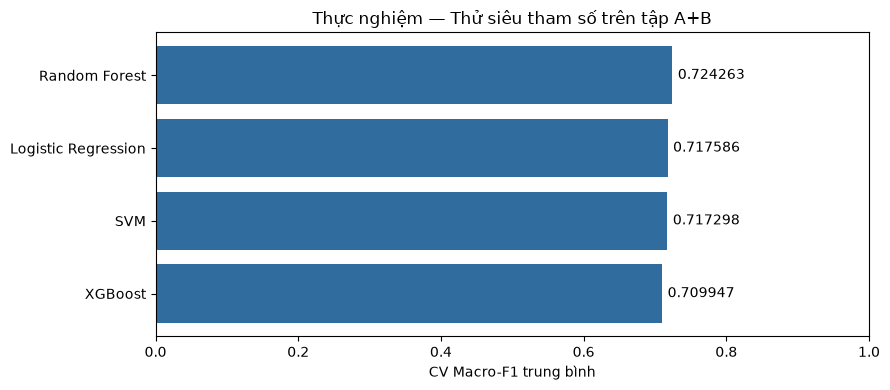

Đã lưu kết quả vào: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-17_ThuThamSo_4MoHinh_TapAB_Khoi
 - ket_qua.xlsx
 - ket_qua_tong_hop.csv
 - diem_tung_fold.csv
 - so_sanh_goc_va_thu.csv
 - so_sanh_macro_f1.png


In [4]:
# Đọc điểm A thử trực tiếp từ file kết quả của notebook tập A, không nhập tay.
a_excel_path = a_output_dir / "ket_qua.xlsx"
if not a_excel_path.is_file():
    raise FileNotFoundError(
        f"Chưa tìm thấy {a_excel_path}. Hãy chạy xong notebook tập A trước, "
        "sau đó chạy lại cell này."
    )

a_results = pd.read_excel(a_excel_path, sheet_name="Tong hop")
required_columns = {"model", "cv_macro_f1"}
if not required_columns.issubset(a_results.columns):
    raise ValueError(
        "Sheet 'Tong hop' trong kết quả tập A phải có các cột model và cv_macro_f1."
    )

ab_trial_scores = results.loc[
    results["configuration"].eq("Thử")
].set_index("model")["cv_macro_f1"]
ab_base_scores = results.loc[
    results["configuration"].eq("Gốc")
].set_index("model")["cv_macro_f1"]
a_trial_scores = a_results.set_index("model")["cv_macro_f1"]

comparison_rows = []
for model_name, item in configs.items():
    if model_name not in a_trial_scores.index:
        raise ValueError(f"Không tìm thấy {model_name} trong kết quả tập A.")
    score_a_trial = float(a_trial_scores.loc[model_name])
    score_ab_base = float(ab_base_scores.loc[model_name])
    score_ab_trial = float(ab_trial_scores.loc[model_name])
    comparison_rows.append({
        "Mô hình": model_name,
        "Tham số thay đổi": item["changed_parameter"],
        "A thử": score_a_trial,
        "A+B Gốc": score_ab_base,
        "A+B Thử": score_ab_trial,
        "Thêm B (A+B Thử - A Thử)": score_ab_trial - score_a_trial,
        "Đổi tham số (A+B Thử - A+B Gốc)": score_ab_trial - score_ab_base,
    })

comparison = pd.DataFrame(comparison_rows).sort_values(
    "A+B Thử", ascending=False
).reset_index(drop=True)
display(comparison.round(6))
output_dir.mkdir(parents=True, exist_ok=True)

excel_path = output_dir / "ket_qua.xlsx"
summary_csv = output_dir / "ket_qua_tong_hop.csv"
fold_csv = output_dir / "diem_tung_fold.csv"
comparison_csv = output_dir / "so_sanh_goc_va_thu.csv"
image_path = output_dir / "so_sanh_macro_f1.png"

run_info = pd.DataFrame([{
    "Người thực hiện": "Nguyễn Hoàng Khởi",
    "Tập đặc trưng": "A+B",
    "Dữ liệu": "data/processed/development.csv",
    "Số mẫu": len(y),
    "Số đặc trưng": X_ab.shape[1],
    "Kiểm định chéo": "StratifiedKFold",
    "Số fold": N_FOLDS,
    "Shuffle": True,
    "Random state": SEED,
    "Chỉ số chính": "CV Macro-F1 trung bình",
    "Thay đổi": (
        "LR: tol 0.0001 -> 0.001; "
        "RF: min_samples_split 2 -> 5; "
        "SVM: shrinking True -> False; "
        "XGBoost: learning_rate 0.1 -> 0.05"
    ),
}])

results.to_csv(summary_csv, index=False, encoding="utf-8-sig")
fold_results.to_csv(fold_csv, index=False, encoding="utf-8-sig")
comparison.to_csv(comparison_csv, index=False, encoding="utf-8-sig")

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    results.to_excel(writer, sheet_name="Tong hop", index=False)
    comparison.round(6).to_excel(writer, sheet_name="So sanh voi tap A", index=False)
    comparison_ab.round(6).to_excel(writer, sheet_name="So sanh goc va thu", index=False)
    fold_results.to_excel(writer, sheet_name="Diem tung fold", index=False)
    config_table.to_excel(writer, sheet_name="Cau hinh mo hinh", index=False)
    run_info.to_excel(writer, sheet_name="Cau hinh luot chay", index=False)
    parameters.to_excel(writer, sheet_name="Tham so day du", index=False)

trial_plot = (
    results.loc[results["configuration"].eq("Thử")]
    .sort_values("cv_macro_f1", ascending=False)
    .reset_index(drop=True)
)
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(trial_plot["model"], trial_plot["cv_macro_f1"], color="#316C9E")
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("CV Macro-F1 trung bình")
ax.set_title("Thực nghiệm — Thử siêu tham số trên tập A+B")
ax.bar_label(bars, fmt="%.6f", padding=4)
fig.tight_layout()
fig.savefig(image_path, dpi=180)
plt.show()
plt.close(fig)

print("Đã lưu kết quả vào:", output_dir.resolve())
for path in (excel_path, summary_csv, fold_csv, comparison_csv, image_path):
    print(" -", path.name)

## 4. Nhận xét
Sau khi chạy xong, dựa vào bảng So sánh cấu hình Gốc và Thử trên A+B và bảng So sánh với tập A để nhận xét:
- Mô hình có CV Macro-F1 cao nhất trong lượt thử trên A+B.
- So sánh CV Macro-F1 của cấu hình Thử với cấu hình Gốc trên cùng tập A+B.
- So sánh kết quả A+B Thử với A Thử để nhận xét thay đổi khi bổ sung hai đặc trưng B.
- Chỉ kết luận trong phạm vi các cấu hình và dữ liệu đã thử; không kết luận dựa trên điểm của một fold riêng lẻ.